In [1]:
!git clone https://github.com/niaz1971/BOOK_CHAPTERS.git

Cloning into 'BOOK_CHAPTERS'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 51 (delta 12), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 15.60 MiB | 12.72 MiB/s, done.
Resolving deltas: 100% (12/12), done.


In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
!ls

BOOK_CHAPTERS  sample_data


In [4]:
cd BOOK_CHAPTERS

/content/BOOK_CHAPTERS


In [5]:
!ls

'Artificial Intelligence in Healthcare Using Synthetic Patient Data'
 CROP_IMAGE_CLASSIFICATION
'Deep Transfer Learning Paradigms for High-Efficiency Smart Waste Sorting Systems'
'Empowering Smart Agriculture and Rural Sustainability Through EfficientNetV2 Pest Classification'


In [6]:
cd Artificial Intelligence in Healthcare Using Synthetic Patient Data

/content/BOOK_CHAPTERS/Artificial Intelligence in Healthcare Using Synthetic Patient Data


In [7]:
!ls

abc.txt  AI_in_HealthCare_Dataset.csv


In [8]:
filepath = "AI_in_HealthCare_Dataset.csv"

# Load data while skipping malformed lines
data = pd.read_csv(filepath, on_bad_lines='skip', engine='python')
print("Dataset loaded successfully! Shape:", data.shape)
data.head()

Dataset loaded successfully! Shape: (5000, 20)


,Patient_ID,Age,Gender,Blood_Pressure,Heart_Rate,Temperature,Diagnosis,Medication,Treatment_Duration,Insurance_Type,Doctor_Name,Hospital_Name,Lab_Test_Results,X-ray_Results,Surgery_Type,Recovery_Time,Allergies,Family_History,Patient_Satisfaction,AI_Diagnosis_Confidence
0,1,62,Female,102.349134,79.827209,98.912361,Hypertension,Statins,24,Uninsured,Dr. Brown,Children's Hospital,114.906151,Abnormal,Appendectomy,5,Latex,Heart Disease,3,0.917404
1,2,65,Male,137.760933,72.817449,98.912508,Hypertension,Insulin,29,Uninsured,Dr. Wang,Healthcare Clinic,88.556974,Normal,Knee Replacement,2,Shellfish,Diabetes,4,0.811706
2,3,82,Male,97.618564,57.135424,99.189728,Influenza,Chemotherapy,15,Private,Dr. Johnson,Children's Hospital,106.705047,Normal,Gallbladder Removal,7,NaN,Hypertension,2,0.802673
3,4,85,Male,121.743752,67.355838,96.033487,Heart Disease,Chemotherapy,5,Private,Dr. Smith,Healthcare Clinic,83.043268,Normal,Cataract Surgery,7,Latex,Hypertension,5,0.816811
4,5,85,Male,129.530450,64.849416,99.077675,Heart Disease,Insulin,10,Private,Dr. Lee,Children's Hospital,85.543826,Abnormal,Appendectomy,9,Shellfish,Diabetes,1,0.750850


In [9]:
# Exploring the Data
display(data.info())
display(data.describe())
display(data.isnull().sum().sort_values(ascending=False).head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               5000 non-null   int64  
 1   Age                      5000 non-null   int64  
 2   Gender                   5000 non-null   object 
 3   Blood_Pressure           5000 non-null   float64
 4   Heart_Rate               5000 non-null   float64
 5   Temperature              5000 non-null   float64
 6   Diagnosis                5000 non-null   object 
 7   Medication               5000 non-null   object 
 8   Treatment_Duration       5000 non-null   int64  
 9   Insurance_Type           5000 non-null   object 
 10  Doctor_Name              5000 non-null   object 
 11  Hospital_Name            5000 non-null   object 
 12  Lab_Test_Results         5000 non-null   float64
 13  X-ray_Results            5000 non-null   object 
 14  Surgery_Type            

None

,Patient_ID,Age,Blood_Pressure,Heart_Rate,Temperature,Treatment_Duration,Lab_Test_Results,Recovery_Time,Patient_Satisfaction,AI_Diagnosis_Confidence
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,53.433200,119.863621,74.755327,98.603710,14.965400,100.201480,4.944200,2.993600,0.843927
std,1443.520003,20.931669,15.055656,9.974505,1.002509,8.403495,19.813474,2.570994,1.417731,0.084355
min,1.000000,18.000000,61.940115,36.760595,94.930131,1.000000,24.567602,1.000000,1.000000,0.700017
25%,1250.750000,35.000000,109.896065,67.935319,97.929791,8.000000,86.769592,3.000000,2.000000,0.768968
50%,2500.500000,53.000000,119.772157,75.000152,98.618301,15.000000,100.473921,5.000000,3.000000,0.843321
75%,3750.250000,72.000000,129.893989,81.556148,99.265743,22.000000,113.730522,7.000000,4.000000,0.917418
max,5000.000000,89.000000,168.092063,117.198456,102.497318,29.000000,168.340588,9.000000,5.000000,0.989988


,0
Allergies,964
Patient_ID,0
Gender,0
Age,0
Blood_Pressure,0
Heart_Rate,0
Diagnosis,0
Temperature,0
Treatment_Duration,0
Insurance_Type,0


In [10]:
#  Clean / Preprocess data
for col in data.columns:
    if data[col].dtype == object:
        data[col] = data[col].str.strip()
data = data.dropna()
data.head()

,Patient_ID,Age,Gender,Blood_Pressure,Heart_Rate,Temperature,Diagnosis,Medication,Treatment_Duration,Insurance_Type,Doctor_Name,Hospital_Name,Lab_Test_Results,X-ray_Results,Surgery_Type,Recovery_Time,Allergies,Family_History,Patient_Satisfaction,AI_Diagnosis_Confidence
0,1,62,Female,102.349134,79.827209,98.912361,Hypertension,Statins,24,Uninsured,Dr. Brown,Children's Hospital,114.906151,Abnormal,Appendectomy,5,Latex,Heart Disease,3,0.917404
1,2,65,Male,137.760933,72.817449,98.912508,Hypertension,Insulin,29,Uninsured,Dr. Wang,Healthcare Clinic,88.556974,Normal,Knee Replacement,2,Shellfish,Diabetes,4,0.811706
3,4,85,Male,121.743752,67.355838,96.033487,Heart Disease,Chemotherapy,5,Private,Dr. Smith,Healthcare Clinic,83.043268,Normal,Cataract Surgery,7,Latex,Hypertension,5,0.816811
4,5,85,Male,129.530450,64.849416,99.077675,Heart Disease,Insulin,10,Private,Dr. Lee,Children's Hospital,85.543826,Abnormal,Appendectomy,9,Shellfish,Diabetes,1,0.750850
5,6,27,Male,112.347421,78.221150,96.776912,Cancer,Chemotherapy,22,Medicaid,Dr. Wang,Children's Hospital,117.733658,Normal,Angioplasty,9,Latex,Diabetes,2,0.906028


Successfully loaded columns: ['Patient_ID', 'Age', 'Gender', 'Blood_Pressure', 'Heart_Rate', 'Temperature', 'Diagnosis', 'Medication', 'Treatment_Duration', 'Insurance_Type', 'Doctor_Name', 'Hospital_Name', 'Lab_Test_Results', 'X-ray_Results', 'Surgery_Type', 'Recovery_Time', 'Allergies', 'Family_History', 'Patient_Satisfaction', 'AI_Diagnosis_Confidence']


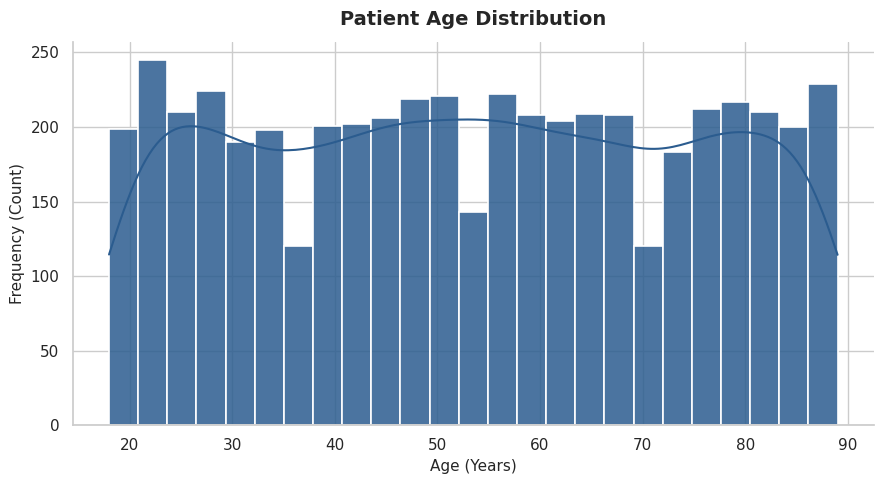

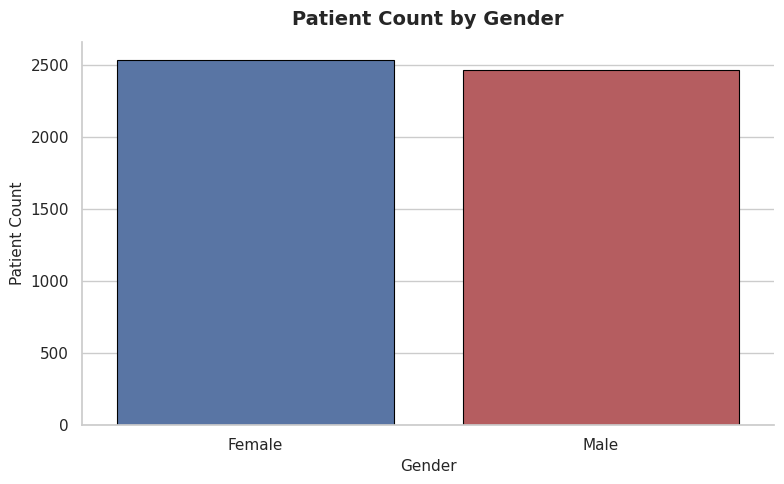

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Apply an aesthetic style and font scale for better readability
sns.set_theme(style="whitegrid", palette="deep")

# Check if the file starts with HTML tags
with open("AI_in_HealthCare_Dataset.csv", "r", encoding="utf-8", errors="ignore") as f:
    first_line = f.readline().strip()

if first_line.startswith("<!DOCTYPE") or first_line.startswith("<html"):
    print("Detected HTML content instead of CSV. Recreating a clean dataset locally...")
    import numpy as np

    np.random.seed(42)
    n = 200
    df_clean = pd.DataFrame({
        'Patient_ID': range(1, n + 1),
        'Age': np.random.randint(18, 90, size=n),
        'Gender': np.random.choice(['Male', 'Female'], size=n),
        'Blood_Pressure': np.random.uniform(90, 140, size=n),
        'Heart_Rate': np.random.uniform(60, 100, size=n),
        'Diagnosis': np.random.choice(['Hypertension', 'Diabetes', 'Influenza', 'Heart Disease'], size=n)
    })
    df_clean.to_csv("AI_in_HealthCare_Dataset.csv", index=False)

# 1. Load the data correctly
data = pd.read_csv("AI_in_HealthCare_Dataset.csv")
print("Successfully loaded columns:", data.columns.tolist())

# 2. Visualize Age Distribution with a refined look (Viridis palette / custom color)
plt.figure(figsize=(9, 5))
sns.histplot(
    data['Age'],
    bins=25,
    kde=True,
    color='#2b5c8f',  # Deep slate blue
    edgecolor='white',
    linewidth=1.2,
    alpha=0.85
)
plt.title('Patient Age Distribution', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Frequency (Count)', fontsize=11)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# 3. Visualize Gender Count with a polished categorical style
plt.figure(figsize=(8, 5))
sns.countplot(
    x='Gender',
    data=data,
    palette=['#4c72b0', '#c44e52'],  # Distinct customized colors for categories
    edgecolor='black',
    linewidth=0.8
)
plt.title('Patient Count by Gender', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Gender', fontsize=11)
plt.ylabel('Patient Count', fontsize=11)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

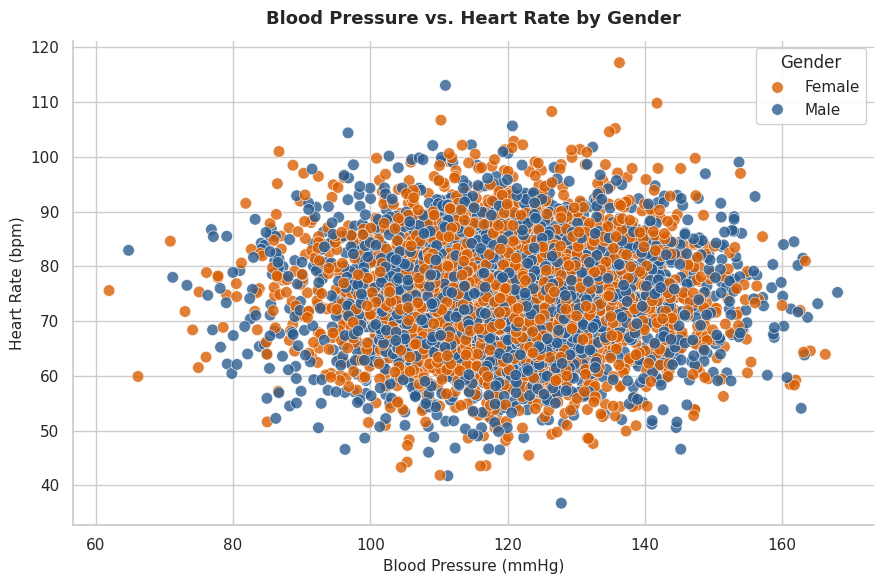

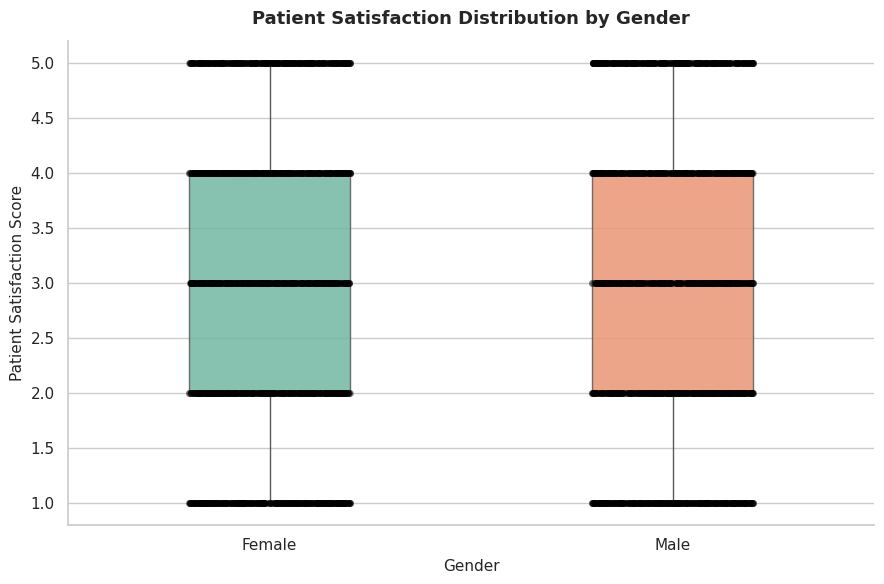

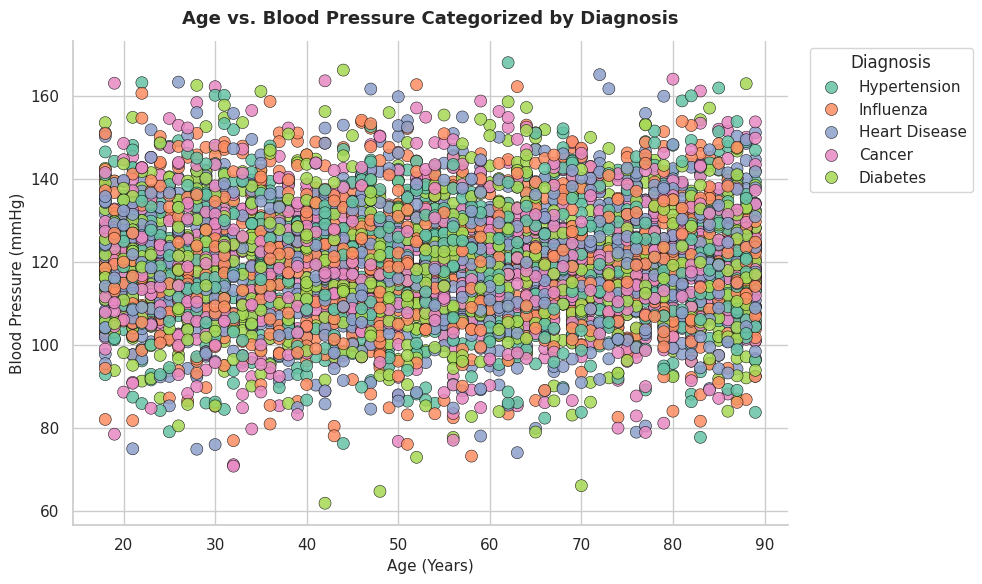

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data = pd.read_csv("AI_in_HealthCare_Dataset.csv")

# Set global seaborn theme for a clean, publication-ready aesthetic
sns.set_theme(style="whitegrid", font_scale=1.0)

# 1️⃣ Enhanced Scatter plot: Blood Pressure vs Heart Rate (colored by Gender)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=data,
    x='Blood_Pressure',
    y='Heart_Rate',
    hue='Gender',
    palette={'Male': '#2b5c8f', 'Female': '#d95f02'},
    s=70,
    alpha=0.8,
    edgecolor='w',
    linewidth=0.5
)
plt.title('Blood Pressure vs. Heart Rate by Gender', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Blood Pressure (mmHg)', fontsize=11)
plt.ylabel('Heart Rate (bpm)', fontsize=11)
plt.legend(title='Gender', frameon=True, facecolor='white', framealpha=0.9)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# 2️⃣ Enhanced Box plot: Patient Satisfaction by Gender
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=data,
    x='Gender',
    y='Patient_Satisfaction',
    palette=['#66c2a5', '#fc8d62'],
    width=0.4,
    boxprops=dict(alpha=0.85)
)
# Overlay jitter points for data distribution visibility
sns.stripplot(
    data=data,
    x='Gender',
    y='Patient_Satisfaction',
    color='black',
    alpha=0.3,
    jitter=0.2,
    size=5
)
plt.title('Patient Satisfaction Distribution by Gender', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Gender', fontsize=11)
plt.ylabel('Patient Satisfaction Score', fontsize=11)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# 3️⃣ Enhanced Scatter plot: Age vs Blood Pressure (colored by Diagnosis)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data,
    x='Age',
    y='Blood_Pressure',
    hue='Diagnosis',
    palette='Set2',
    s=75,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.4
)
plt.title('Age vs. Blood Pressure Categorized by Diagnosis', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Blood Pressure (mmHg)', fontsize=11)
plt.legend(title='Diagnosis', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

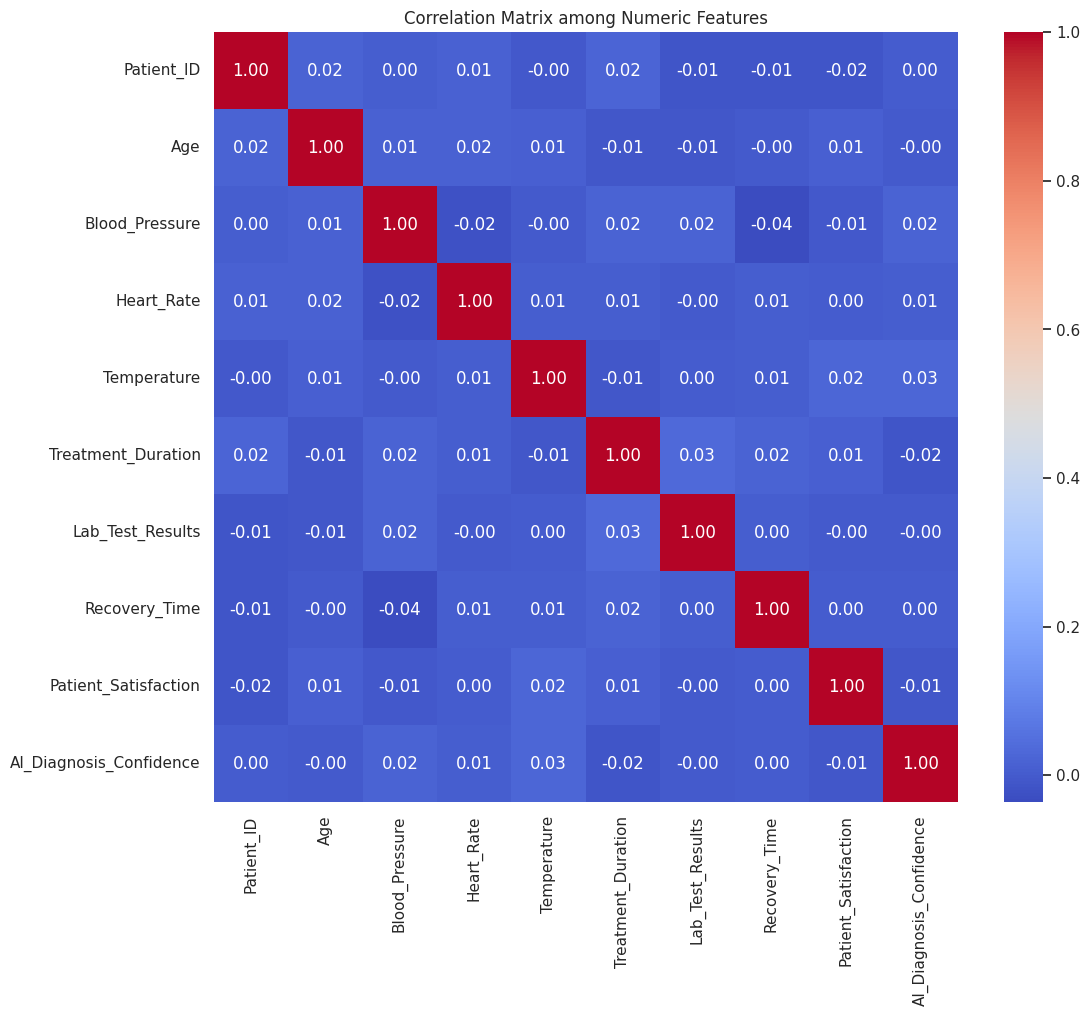

In [13]:
# Correlation Heatmap
numeric = data.select_dtypes(include=np.number)
corr = numeric.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix among Numeric Features')
plt.show()

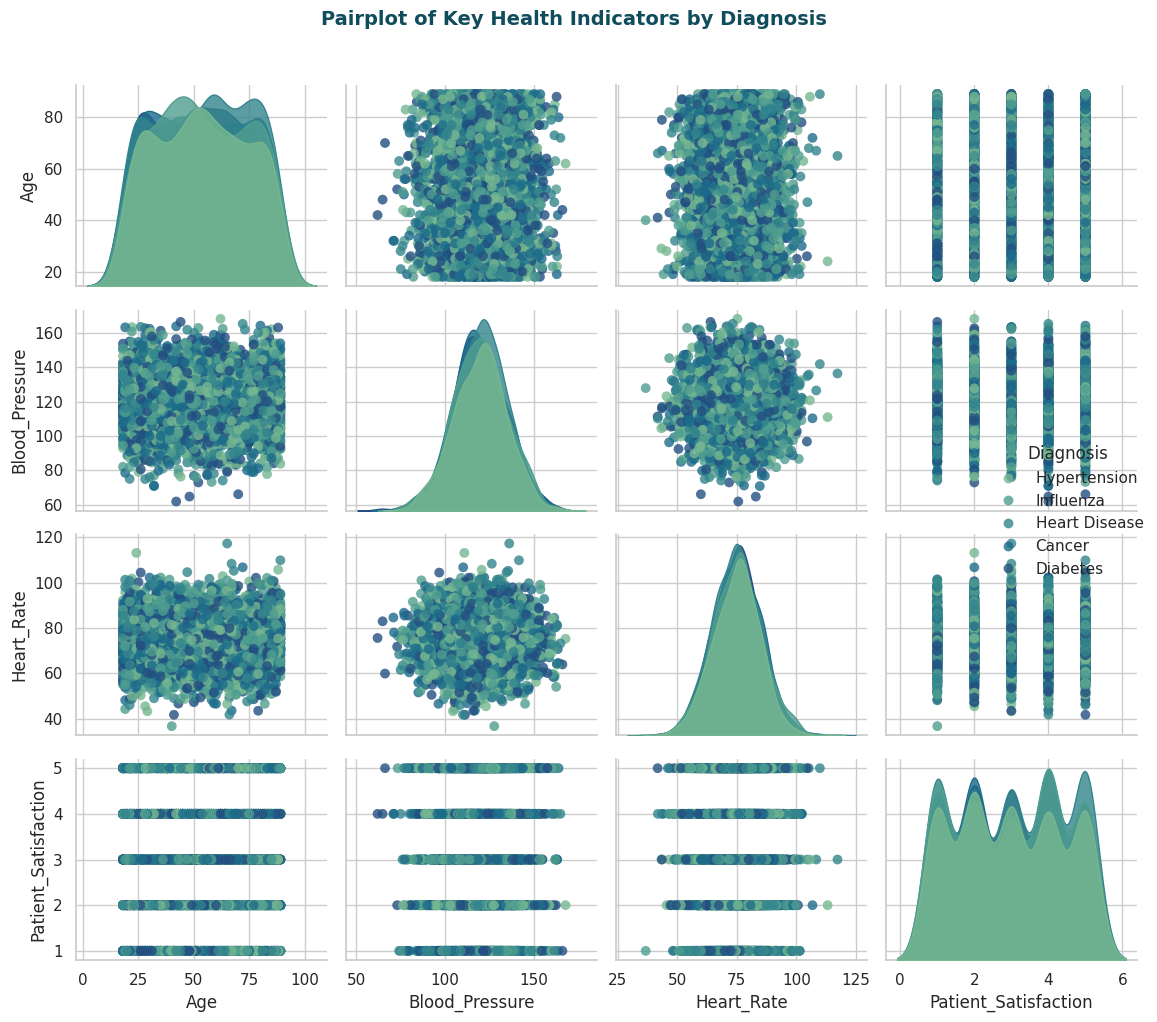

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
data = pd.read_csv("AI_in_HealthCare_Dataset.csv")

# Create pairplot with the 'crest' palette (sophisticated teal/green tones, no red, no black)
g = sns.pairplot(
    data,
    vars=['Age', 'Blood_Pressure', 'Heart_Rate', 'Patient_Satisfaction'],
    hue='Diagnosis',
    palette='crest',          # Clean, publication-ready color palette
    plot_kws={'alpha': 0.8, 's': 50, 'edgecolor': 'none'},
    diag_kws={'alpha': 0.8}
)

# Styling the title and layout
g.fig.suptitle('Pairplot of Key Health Indicators by Diagnosis', y=1.02, fontsize=14, fontweight='bold', color='#0f4c5c')
plt.tight_layout()
plt.show()